Link Tableu : https://public.tableau.com/app/profile/putri.joeliya/viz/P1W1D4AM/ANALISISRISIKOKREDITDEFAULT?publish=yes

Melakukan analisis risiko kredit dan faktor risiko gagal bayar (credit risk analysis)

## Topik 
perusahaan pemberi pinjaman sedang menghadapi tantangan risiko kerugian finansial akibat nasabah yang mengalami gagal bayar, untuk bisa meminimalisir risiko ini, divisi manajemen risiko perlu memahiami profil nasabah serta faktor faktor finansial yang memicu keterlambatan atau kegagalan pembayaran pinjaman. 

### Problem Steatment (SMART)
menganalisis faktor utama penyebab gagal bayar pinjaman untuk mengevaluasi profil pada nasabah dan merekomendasikan penyesuaian batasan risiko guna menekan tingkat default pada portofolio pinjaman perusahaan selama periode analisis. 

* Specific : Menganalisis faktor risiko utama pemicu gagal bayar (loan default), fokus pada suku bunga (loan_int_rate), beban utang (loan_percent_income), kelas kredit (loan_grade), dan status rumah.
* Measurable : Membuktikan perbedaan suku bunga via Welch's t-test (alpha = 0.05), mengukur tingkat default per grade, dan menetapkan threshold rasio beban utang aman.
* Achievable : Dapat dieksekusi menggunakan teknik EDA, pengujian hipotesis, dan visualisasi data Python/Tableau pada 31,522 data nasabah bersih.
* Relevant : Menurunkan rasio Non-Performing Loan (NPL) dan mengoptimalkan strategi risk-based pricing pada portofolio kredit bank.
* Time-bound : Rekomendasi kebijakan risko dan credit dashboard harus rampung dan disajikan ke jajaran Risk Management & Credit Risk Officer Perusahaan Pembiayaan dalam 2 minggu sebelum penetapan target kuartal depan.

### User/Client Target
Risk Management Team & Credit Risk Officer Perusahaan Pembiayaan 

### Penjabaran Masalah: 
* Bagaimanakah distribusi tingkat gagal bayar berdasarkan tujuan pinjaman?
* bagaimana perbandingan proporsi gagal bayar pada tiap tingkatan kelas pinjaman?
* apakah statu kepemilikan rumah mempengaruhi besarnya rasio pinjaman terhadap pendapatan?
* bagaimana sebaran jumlah pinjaman berdasarkan tingkat suku bunga untuk nasabah yang default vs non-default?
* bagaimanakah pemusatan dan penyebaran dari perusahaan nasabah serta rasio beban pinjaman, dan apakah terdapat indikasi outlier ekstreme? 
* apakah terdapat perbedaan rata rata suku bunga yang signifikan antara nasabah yang mengalami gagal bayar dan nasabah yang lancar?


## Data Loading dan Cleaning  

In [29]:
import pandas as pd
import numpy as np
df = pd.read_csv('credit_risk_dataset.csv', low_memory=False)
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [31]:
print(len(df))

32581


### Menghapus data yang duplikat 

In [32]:
df = df.drop_duplicates()

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  object 
 3   person_emp_length           31529 non-null  float64
 4   loan_intent                 32416 non-null  object 
 5   loan_grade                  32416 non-null  object 
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               29321 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_default_on_file   32416 non-null  object 
 11  cb_person_cred_hist_length  32416 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.2+ MB


In [34]:
print(len(df))

32416


### Menghapus Data Anomali 

Membersihkan data data anomali seperti umur yang lebih dari 100 tahun dan masa kerja yang bedara di atas 100 tahun 

In [35]:
df = df[df['person_age'] <= 100] 
df = df[df['person_emp_length'] <= 100] 

### Missing Value 

Mengisi Missing Value dengan median pada kolom yang terdapat baris kosong seperti masa kerja dan suku bunga pinjaman.

In [36]:
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())
df['loan_int_rate'] = df.groupby ('loan_grade')['loan_int_rate'].transform(lambda x: x.fillna(x.median()))

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31522 entries, 1 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  31522 non-null  int64  
 1   person_income               31522 non-null  int64  
 2   person_home_ownership       31522 non-null  object 
 3   person_emp_length           31522 non-null  float64
 4   loan_intent                 31522 non-null  object 
 5   loan_grade                  31522 non-null  object 
 6   loan_amnt                   31522 non-null  int64  
 7   loan_int_rate               31522 non-null  float64
 8   loan_status                 31522 non-null  int64  
 9   loan_percent_income         31522 non-null  float64
 10  cb_person_default_on_file   31522 non-null  object 
 11  cb_person_cred_hist_length  31522 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.1+ MB


In [38]:
df


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [39]:
print(len(df))

31522


## Analisa Deskriptif 

In [40]:
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

### Statistik Berdasarkan `person_income` 

In [41]:
print('Average of person Income:',df['person_income'].mean())

print('Median of Person Income:',df['person_income'].median())

std = df['person_income'].std()

print('Standard Deviation of Person Income:',std)

print(f"Skewness: {df['person_income'].skew()}")

Average of person Income: 66501.6839350295
Median of Person Income: 56000.0
Standard Deviation of Person Income: 52752.156210712164
Skewness: 9.837390915423446


Rata rata pendapatan sebesat `$66,501` dimana nilai ini sangat berjauhan dengan hasil nilai median yaitu `$56,000`. Di jelaskan juga terhadap nilai skweness yang dihasilkan sebedar `9.89` angka ini di nilai sebagai high skewed yang menunjukan bahwa distribusi pendapatan sangat miring ke kanan. 

Sebagian besar individu berada pada tingkat pendapatan menengah ke bawah dan sisanya hanya sedikit yang memiliki penghasilan sangat tinggi yang mendistorsi hasil penilaian rata rata. 

### Statistik Berdasarkan `loan_percent_income` 

In [42]:
print('Average of loan ratio:',df['loan_percent_income'].mean())

print('Median of loan ratio:',df['loan_percent_income'].median())

std = df['loan_percent_income'].std()

print('Standard Deviation of loan ratio:',std)

print(f"Skewness: {df['loan_percent_income'].skew()}")

Average of loan ratio: 0.1696580166233107
Median of loan ratio: 0.15
Standard Deviation of loan ratio: 0.10629578956955339
Skewness: 1.0678682802098685


Rata rata rasio pinjaman terhadap pendapatan adalah 17% dengan median 15%, serta nilai skewness sebesar 1.07. Rasio ini tergolong kedalam miring positif, dimana mayoritas peminjam mengambil porsi pinjaman yang relatif aman dari total pendapatan mereka 

### Analisi Outlier

<Axes: >

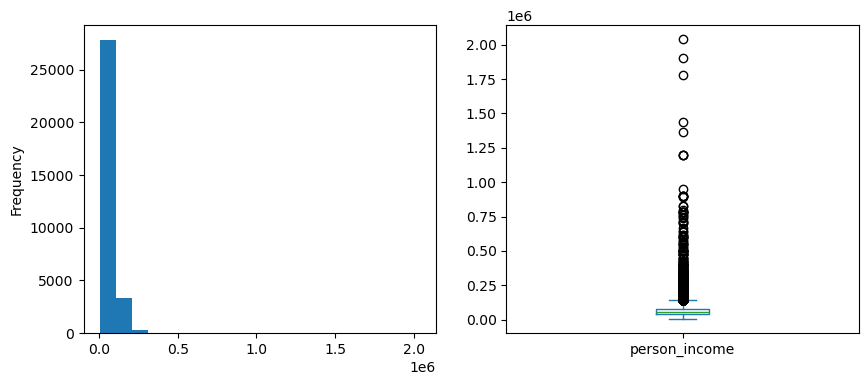

In [43]:
fig, ax = plt.subplots(ncols=2,figsize=(10,4))
df['person_income'].plot(kind='hist',bins=20,ax=ax[0])
df['person_income'].plot(kind='box',ax=ax[1])

#### Z-Score

In [44]:
avg = df['person_income'].mean()
std = df['person_income'].std()

up_bound = avg + 3*std
low_bound = avg - 3*std

print(f'Upper Boundary: {up_bound:.2f}' )
print(f'Lower Boundary: {low_bound:.2f}')

Upper Boundary: 224758.15
Lower Boundary: -91754.78


In [45]:
outlier = df['person_income'][(df['person_income']<low_bound) | (df['person_income']>up_bound)]
no_outlier = df['person_income'][(df['person_income']>=low_bound) & (df['person_income']<=up_bound)]

print(f'Percentage of outliers: {len(outlier)*100/len(df['person_income']):.2f}%%')

Percentage of outliers: 1.10%%


<Axes: >

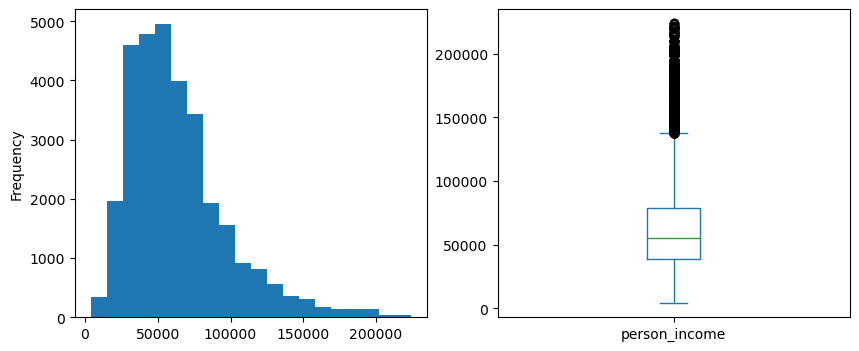

In [46]:
fig, ax = plt.subplots(ncols=2,figsize=(10,4))

no_outlier.plot(kind='hist',bins=20,ax=ax[0])
no_outlier.plot(kind='box',ax=ax[1])

#### Tukey

In [47]:
q1 = df['person_income'].quantile(0.25)
q3 = df['person_income'].quantile(0.75)
iqr = q3-q1

up_bound = q3 + 1.5*iqr
low_bound = q1 - 1.5*iqr

print(f'Upper Boundary: {up_bound:.2f}' )
print(f'Lower Boundary: {low_bound:.2f}')

Upper Boundary: 140843.00
Lower Boundary: -21405.00


In [48]:
outlier = df['person_income'][(df['person_income']<low_bound) | (df['person_income']>up_bound)]
no_outlier = df['person_income'][(df['person_income']>=low_bound) & (df['person_income']<=up_bound)]

print(f'Percentage of outliers: {len(outlier)*100/len(df['person_income']):.2f}%%')

Percentage of outliers: 4.62%%


<Axes: >

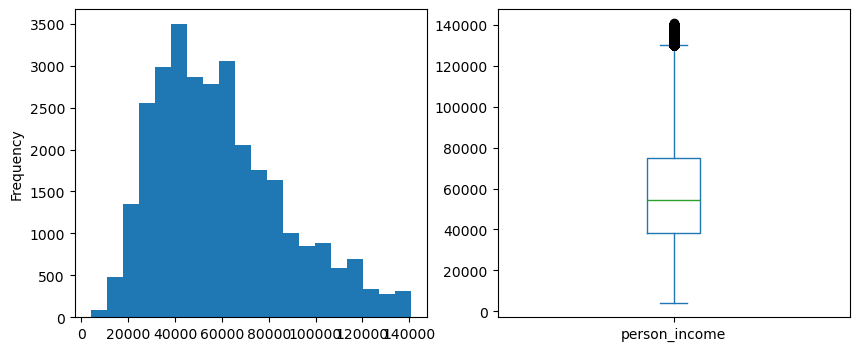

In [49]:
fig, ax = plt.subplots(ncols=2,figsize=(10,4))

no_outlier.plot(kind='hist',bins=20,ax=ax[0])
no_outlier.plot(kind='box',ax=ax[1])

Hasil analisis menggambarkan hasil yang lebih stabil dibandingkan zscore ketika di bandingkan makan pada analisis ini tukey merupkan pilihan yang tepat untuk bisa melihat outlier dengan hasil 4.62% outliers terdapat pada dataset yang ada ini memang mengartikan bawha kebanyakan outlier memiliki penghasilan di atas rata rata yang cukup tinggi.

## Statistik Inferensial 

In [50]:
default_rate = df[df['loan_status']==1]['loan_int_rate']
non_default_rate = df[df['loan_status']==0]['loan_int_rate']

In [51]:
print('Average of default =',default_rate.mean())
print('Average of non default =',non_default_rate.mean())

Average of default = 13.112569413838697
Average of non default = 10.479179850293344


#### Hipotesis
> H0 : Tidak ada perbedaan rata rata suku bungan antara nasabah yang default dan non default 


> H1 : Terdapat perbedaan rata rata suku bungan yang signifikan antara kedua kelompok 

alpha = 5% / 0.05.

In [52]:
t_stat, p_val = stats.ttest_ind(default_rate, non_default_rate, equal_var=False)
print('T-Statistic:',t_stat)
print('P-value:',p_val)

T-Statistic: 60.468599684027566
P-value: 0.0


H0 di tolak 

>Kesimpulan:
>Terdapat perbedaan rata rata antara suku bunga yang signifikan secara ststistik antara nasabah yang default dan non default sekita 25% lebih tinggi 

## Visualisasi Data 

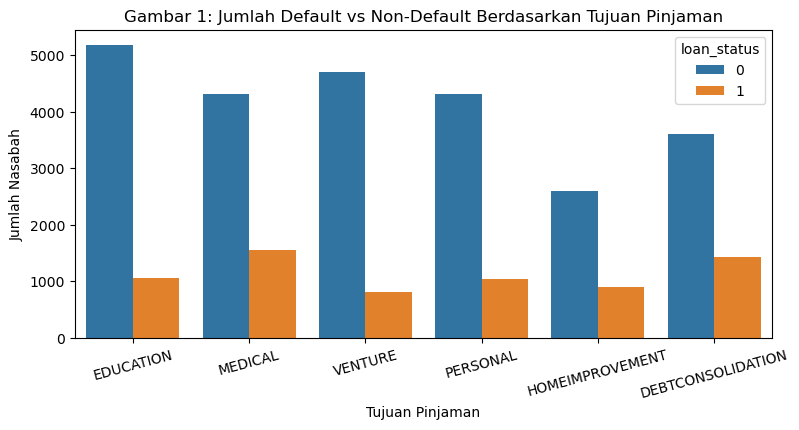

In [53]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df, x='loan_intent', hue='loan_status')
plt.title('Gambar 1: Jumlah Default vs Non-Default Berdasarkan Tujuan Pinjaman')
plt.xlabel('Tujuan Pinjaman')
plt.ylabel('Jumlah Nasabah')
plt.xticks(rotation=15)
plt.show()

Pengajuan pinjaman terbanyak berada pada kategori education yang di susul oleh venture dan debconsolidation. lalu, persebaran gagal bayar juga paling tinggi secara jumlah terlihat pada kategori medical dan debconsolidation. 

>Implikasi : Meskipun education memiliki volume pengajuan yang sangat tinggi, pinjaman untuk kebutuhan medical dan konsolidasi utang menunjukan proporsi batang orange yang relatif lebih besar terhadap total pengajuan. 

C:\Users\E480\AppData\Local\Temp\ipykernel_23216\1299098061.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='loan_grade', y='loan_status', ci=None)


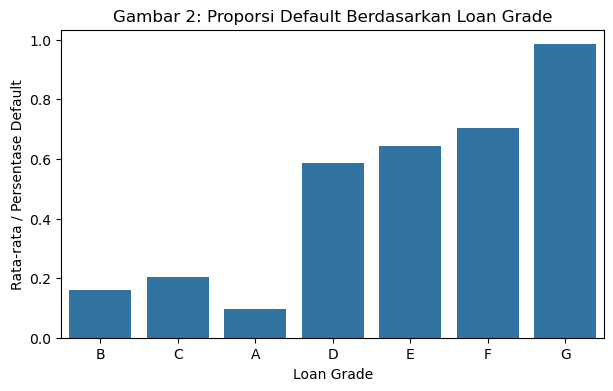

In [54]:
plt.figure(figsize=(7, 4))
# ci=None untuk menghilangkan garis error bar agar lebih bersih
sns.barplot(data=df, x='loan_grade', y='loan_status', ci=None) 
plt.title('Gambar 2: Proporsi Default Berdasarkan Loan Grade')
plt.xlabel('Loan Grade')
plt.ylabel('Rata-rata / Persentase Default')
plt.show()

Terdapat hubungan positif yang sangat kuat antara tingkat grade pinjaman dengan risiko gagal bayar dimana semakin rendah grade kreditnya maka semakin tinggi persentase defaultnya. pada grafik di ata di jelaskan bahwa kategori risiko rendah di pegang oleh grade A-C dan katergori resiko tinggidi miliki oleh grade D-G dengan persentase puncak yang di miliki grade D mendekati 100 persen 

>Implikasi : Semakin tinggi grade yang di miliki maka resiko gagal bayar akan semakin tinggi 

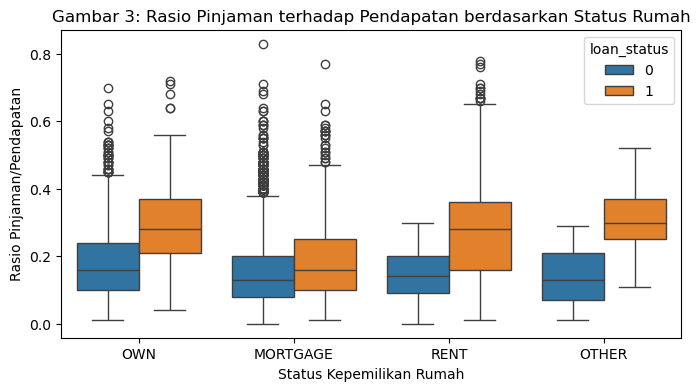

In [55]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='person_home_ownership', y='loan_percent_income', hue='loan_status')
plt.title('Gambar 3: Rasio Pinjaman terhadap Pendapatan berdasarkan Status Rumah')
plt.xlabel('Status Kepemilikan Rumah')
plt.ylabel('Rasio Pinjaman/Pendapatan')
plt.show()

Pada setiap nasabah pada kategori kepemilikan tempat tinggal dapat dilihat bahwa rata rata kotak orange memiliki posisi yang lebih tinggi pada setiap kategorinya. Selain itu nilai median rasio pinjaman terjahadap pinjaman cukup tinggi sekitar 25% - 30%. dan jika di bandingkan dengan nasabah yang non default ini menjelaskan hasil yang cukup jauh sekitas 10% -15%. 

>Risiko : Pada grafik terlihat bahwa tempat tinggal yang berstatus rent memiliki sebaran outlier rasio beban krdit paling tinggi mencapai lebih dari 60% dan berasosiasi kuat dengan meningkatnya gagal bayar.

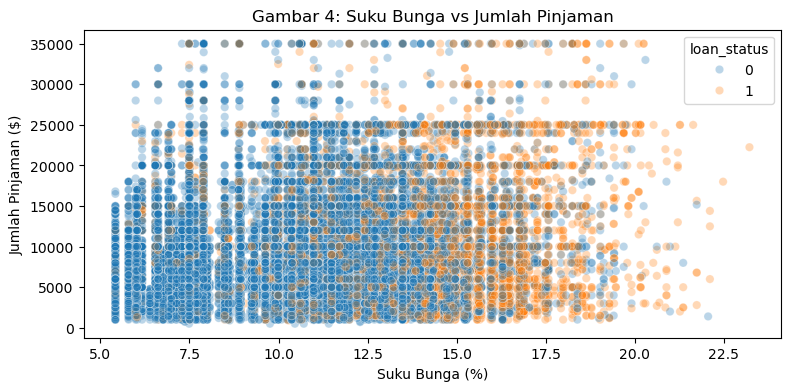

In [56]:
plt.figure(figsize=(9, 4))
sns.scatterplot(data=df, x='loan_int_rate', y='loan_amnt', hue='loan_status', alpha=0.3)
plt.title('Gambar 4: Suku Bunga vs Jumlah Pinjaman')
plt.xlabel('Suku Bunga (%)')
plt.ylabel('Jumlah Pinjaman ($)')
plt.show()

Dapat dilihat bahwa sebaran titik default terkonsentrasi cukup padat pasa porsi suku bunga tinggi di atas 12.5 persen. Sebagian besar kasus default terjadi pada pinjaman nominal sedang hingga ke besar yang membebani suku bunga relatif tinggi. 

>Implikasi : Suku bungan rendah membantu menjaga kelancaran pembayaran.

## Kesimpulan 
### Pengambilan Kesimpulan

#### Evaluasi Problem Statement & Hasil Analisis
Problem statement awal : Menganalisis faktor-faktor risiko utama penyebab gagal bayar pinjaman (`loan_status`) untuk mengevaluasi profil nasabah dan merekomendasikan penyesuaian batasan risiko kredit guna menekan tingkat default pada portofolio pinjaman perusahaan.

Berdasarkan seluruh analisis statistik deskriptif, inferensial, dan visualisasi data terhadap 31,522 nasabah, di jelaskan sebagai berikut:
1. **Sensitivitas Suku Bunga:** Hasil uji hipotesis membuktikan secara signifikan p-value < 0.05 bahwa nasabah yang default menanggung rata-rata suku bunga jauh lebih tinggi (13.11%) dibanding nasabah lancar (10.48%).
2. **Tingkat Risiko Kredit (Loan Grade):** Risiko gagal bayar berbanding lurus dengan kelas kredit. Nasabah pada Grade A–C tergolong relatif aman < 20% default, sedangkan Grade D–G tergolong kritis di mana lebih dari 58% hingga 98% nasabah mengalami gagal bayar.
3. **Beban Utang & Status Rumah:** Nasabah berstatus sewa (`RENT`) yang memiliki rasio pinjaman terhadap pendapatan (`loan_percent_income`) melebihi 25% menunjukkan kecenderungan default paling dominan.
4. **Tujuan Pinjaman:** Kategori pinjaman Medis (`MEDICAL`) dan Konsolidasi Utang (`DEBTCONSOLIDATION`) menyumbang frekuensi gagal bayar terbesar.

#### Rekomendasi Bisnis (Actionable Solutions)
1. **Penerapan Threshold Beban Utang:** Membatasi rasio *loan_percent_income* maksimal di angka **20%–25%**, terutama bagi calon debitur yang belum memiliki rumah pribadi.
2. **Evaluasi Penyaluran Kredit Grade Tinggi:** Memperketat kriteria kelayakan atau membatasi plafon kredit untuk pengajuan pada **Loan Grade D, E, F, dan G**.
3. **Penyesuaian Skema Suku Bunga:** Menerapkan skema *risk-based pricing* yang lebih fleksibel untuk mencegah penumpukan beban bunga ekstrem yang memicu keterlambatan bayar.



In [57]:
df.to_csv('credit_risk_clean.csv', index=False)